## Preface Images

In [16]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:70% !important; }</style>"))

In [17]:
from colors_map import *
raw_level_color_schemes = """
        .BYTE M_GRAY1,M_GRAY3,M_ORANGE,M_YELLOW,M_ORANGE  ; Level 1
        .BYTE M_BLACK,M_GRAY1,M_LTBLUE,M_LTRED,M_RED      ; Level 2, Level 13
        .BYTE M_BROWN,M_ORANGE,M_ORANGE,M_LTGREEN,M_GREEN ; Level 3, Level 11
        .BYTE M_GRAY1,M_GRAY3,M_ORANGE,M_LTBLUE,M_BLUE    ; Level 4
        .BYTE M_GREEN,M_LTGREEN,M_ORANGE,M_LTBLUE,M_BLUE  ; Level 5
        .BYTE M_ORANGE,M_YELLOW,M_ORANGE,M_GRAY2,M_BLACK  ; Level 6
        .BYTE M_GRAY1,M_CYAN,M_LTGREEN,M_LTRED,M_RED      ; Level 7
        .BYTE M_BLACK,M_GRAY2,M_LTRED,M_LTBLUE,M_BLUE     ; Level 8
        .BYTE M_BLUE,M_LTBLUE,M_ORANGE,M_LTGREEN,M_GREEN  ; Level 9 , Level 14
        .BYTE M_GRAY1,M_GRAY2,M_GRAY2,M_LTRED,M_RED       ; Level 10
        .BYTE M_BROWN,M_ORANGE,M_ORANGE,M_LTGREEN,M_GREEN ; Level 3, Level 11
        .BYTE M_BLUE,M_CYAN,M_ORANGE,M_GRAY2,M_GRAY1      ; Level 12
        .BYTE M_BLACK,M_GRAY1,M_LTBLUE,M_LTRED,M_RED      ; Level 2, Level 13
        .BYTE M_BLUE,M_LTBLUE,M_ORANGE,M_LTGREEN,M_GREEN  ; Level 9 , Level 14
        .BYTE M_RED,M_LTRED,M_ORANGE,M_YELLOW,M_ORANGE    ; Level 15
"""
raw_level_color_schemes = [l[14:57].split(',') for l in raw_level_color_schemes.split('\n')][1:-1]
raw_level_color_schemes = [[x.strip() for x in l] for l in raw_level_color_schemes]
#raw_level_color_schemes = [v for l in raw_level_color_schemes for v in l]
#surface_ram = [temp_surface_ram[v:v+80] for v in range(0, len(temp_surface_ram), 80)]
#surface_ram = ["$"+x.upper() for x in flatten(surface_ram)]
level_colors = [None]
for l in raw_level_color_schemes:
    colors = (color_constants[l[1]], "c64_black", color_constants[l[0]], "c64_white")
    level_colors += [colors]

# The character sets each level uses.
level_charsets = [0,2,0,2,0,1,2,1,0,1,2,0,2,1,0,2]

level_names = [None, "Zinc","Lead","Copper","Silver","Iron","Gold","Platinum","Tungsten","Iridon","Kallisto","Tri-alloy","Quadmium","Ergonite","Galactium","Uridium"]

In [18]:
level_colors

[None,
 ('c64_gray3', 'c64_black', 'c64_gray1', 'c64_white'),
 ('c64_gray1', 'c64_black', 'c64_black', 'c64_white'),
 ('c64_orange', 'c64_black', 'c64_brown', 'c64_white'),
 ('c64_gray3', 'c64_black', 'c64_gray1', 'c64_white'),
 ('c64_ltgreen', 'c64_black', 'c64_green', 'c64_white'),
 ('c64_yellow', 'c64_black', 'c64_orange', 'c64_white'),
 ('c64_cyan', 'c64_black', 'c64_gray1', 'c64_white'),
 ('c64_lightgray', 'c64_black', 'c64_black', 'c64_white'),
 ('c64_ltblue', 'c64_black', 'c64_blue', 'c64_white'),
 ('c64_lightgray', 'c64_black', 'c64_gray1', 'c64_white'),
 ('c64_orange', 'c64_black', 'c64_brown', 'c64_white'),
 ('c64_cyan', 'c64_black', 'c64_blue', 'c64_white'),
 ('c64_gray1', 'c64_black', 'c64_black', 'c64_white'),
 ('c64_ltblue', 'c64_black', 'c64_blue', 'c64_white'),
 ('c64_ltred', 'c64_black', 'c64_red', 'c64_white')]

### Get the Manta Sprite

In [19]:
from PIL import Image

FACTOR = 15

def get_surface_snippet(level=1, x_offset=600, y_offset = 0, width=1000, height = 200):
    img = Image.open(f"bullets_player/surface_diagrams/{level}_no_text.png")
    img = img.crop((x_offset, y_offset, x_offset + width, y_offset + height))
    #img = img.resize((int(img.width * 2), int(img.height * 2)), Image.NEAREST)
    return img

def get_surface_character_snippet(level=1, x_offset=600, y_offset = 0, width=1000, height = 200):
    img = Image.open(f"surface_character_set_diagrams/surface_diagrams/{level}.png")
    img = img.crop((x_offset, y_offset, x_offset + width, y_offset + height))
    #img = img.resize((int(img.width * 2), int(img.height * 2)), Image.NEAREST)
    return img

def make_shadow(img, color):
    color = ImageColor.getrgb(c64_to_rgb[color])
    d = img.getdata()
    new_image = []
    for item in d:
        if item[3] == 0:
            new_image.append(item)
        else:
            new_image.append(color)
    # update image data
    img.putdata(new_image)
    return img

resize = lambda img,factor: img.resize((int(img.width * factor), int(img.height * factor)), Image.NEAREST)
add_offset = lambda a,b : [sum(x) for x in zip(a,b)]
scale = lambda x: x * FACTOR
cells = lambda x: x * 120

In [24]:
from PIL import Image, ImageDraw, ImageColor

c64_to_rgb = {
"c64_black": "#000000",     
"c64_white": "#ffffff",     
"c64_red": "#813338",       
"c64_cyan":  "#75cec8",     
"c64_purple": "#8e3c97",    
"c64_green": "#56ac4d",     
"c64_blue":  "#2e2c9b",     
"c64_yellow":  "#edf171",   
"c64_orange":  "#8e5029",   
"c64_brown": "#553800",     
"c64_ltred": "#c46c71",  
"c64_gray1":  "#4a4a4a",    
"c64_lightgray": "#7b7b7b", 
"c64_ltgreen": "#a9ff9f",
"c64_ltblue":  "#706deb",
"c64_gray3": "#b2b2b2",                             
}
img = Image.open("manta_sprites/0_MANTA1.png")
img = resize(img, FACTOR)
manta = img.copy()

### Get the Stars


In [ ]:
small_star = Image.open("surface_characters/1_42.png")
big_star = Image.open("surface_characters/1_43.png")

### Draw The Star Background 

In [ ]:
import random
def addStarsToRow(background, row):
    for x in range(0,38):
        r = random.randint(0,255)
        if r < 240:
            continue
        if r < 248:
            background.paste(small_star, (cells(x), cells(row)), mask=small_star)
            continue
        background.paste(big_star, (cells(x), cells(row)), mask=big_star)
    return background

In [ ]:
def make_mask(i):
    img = i.copy()
    d = img.getdata()
    new_image = []
    for item in d:
        if item[3] != 0:
            new_image.append((0xff, 0xff, 0xff))
        else:
            new_image.append((0,0,0))
    # update image data
    img.putdata(new_image)
    return img


In [ ]:
import random
def addRandomStar(background):
    rx = random.randint(0,31)
    if rx < 20:
        rx+=4
    ry = random.randint(7,22)
    rs = random.randint(0,1)
    background.paste(small_star if rs else big_star, (cells(rx), cells(ry)), mask=small_star if rs else big_star)
    return background

### Full Star Background Rendering

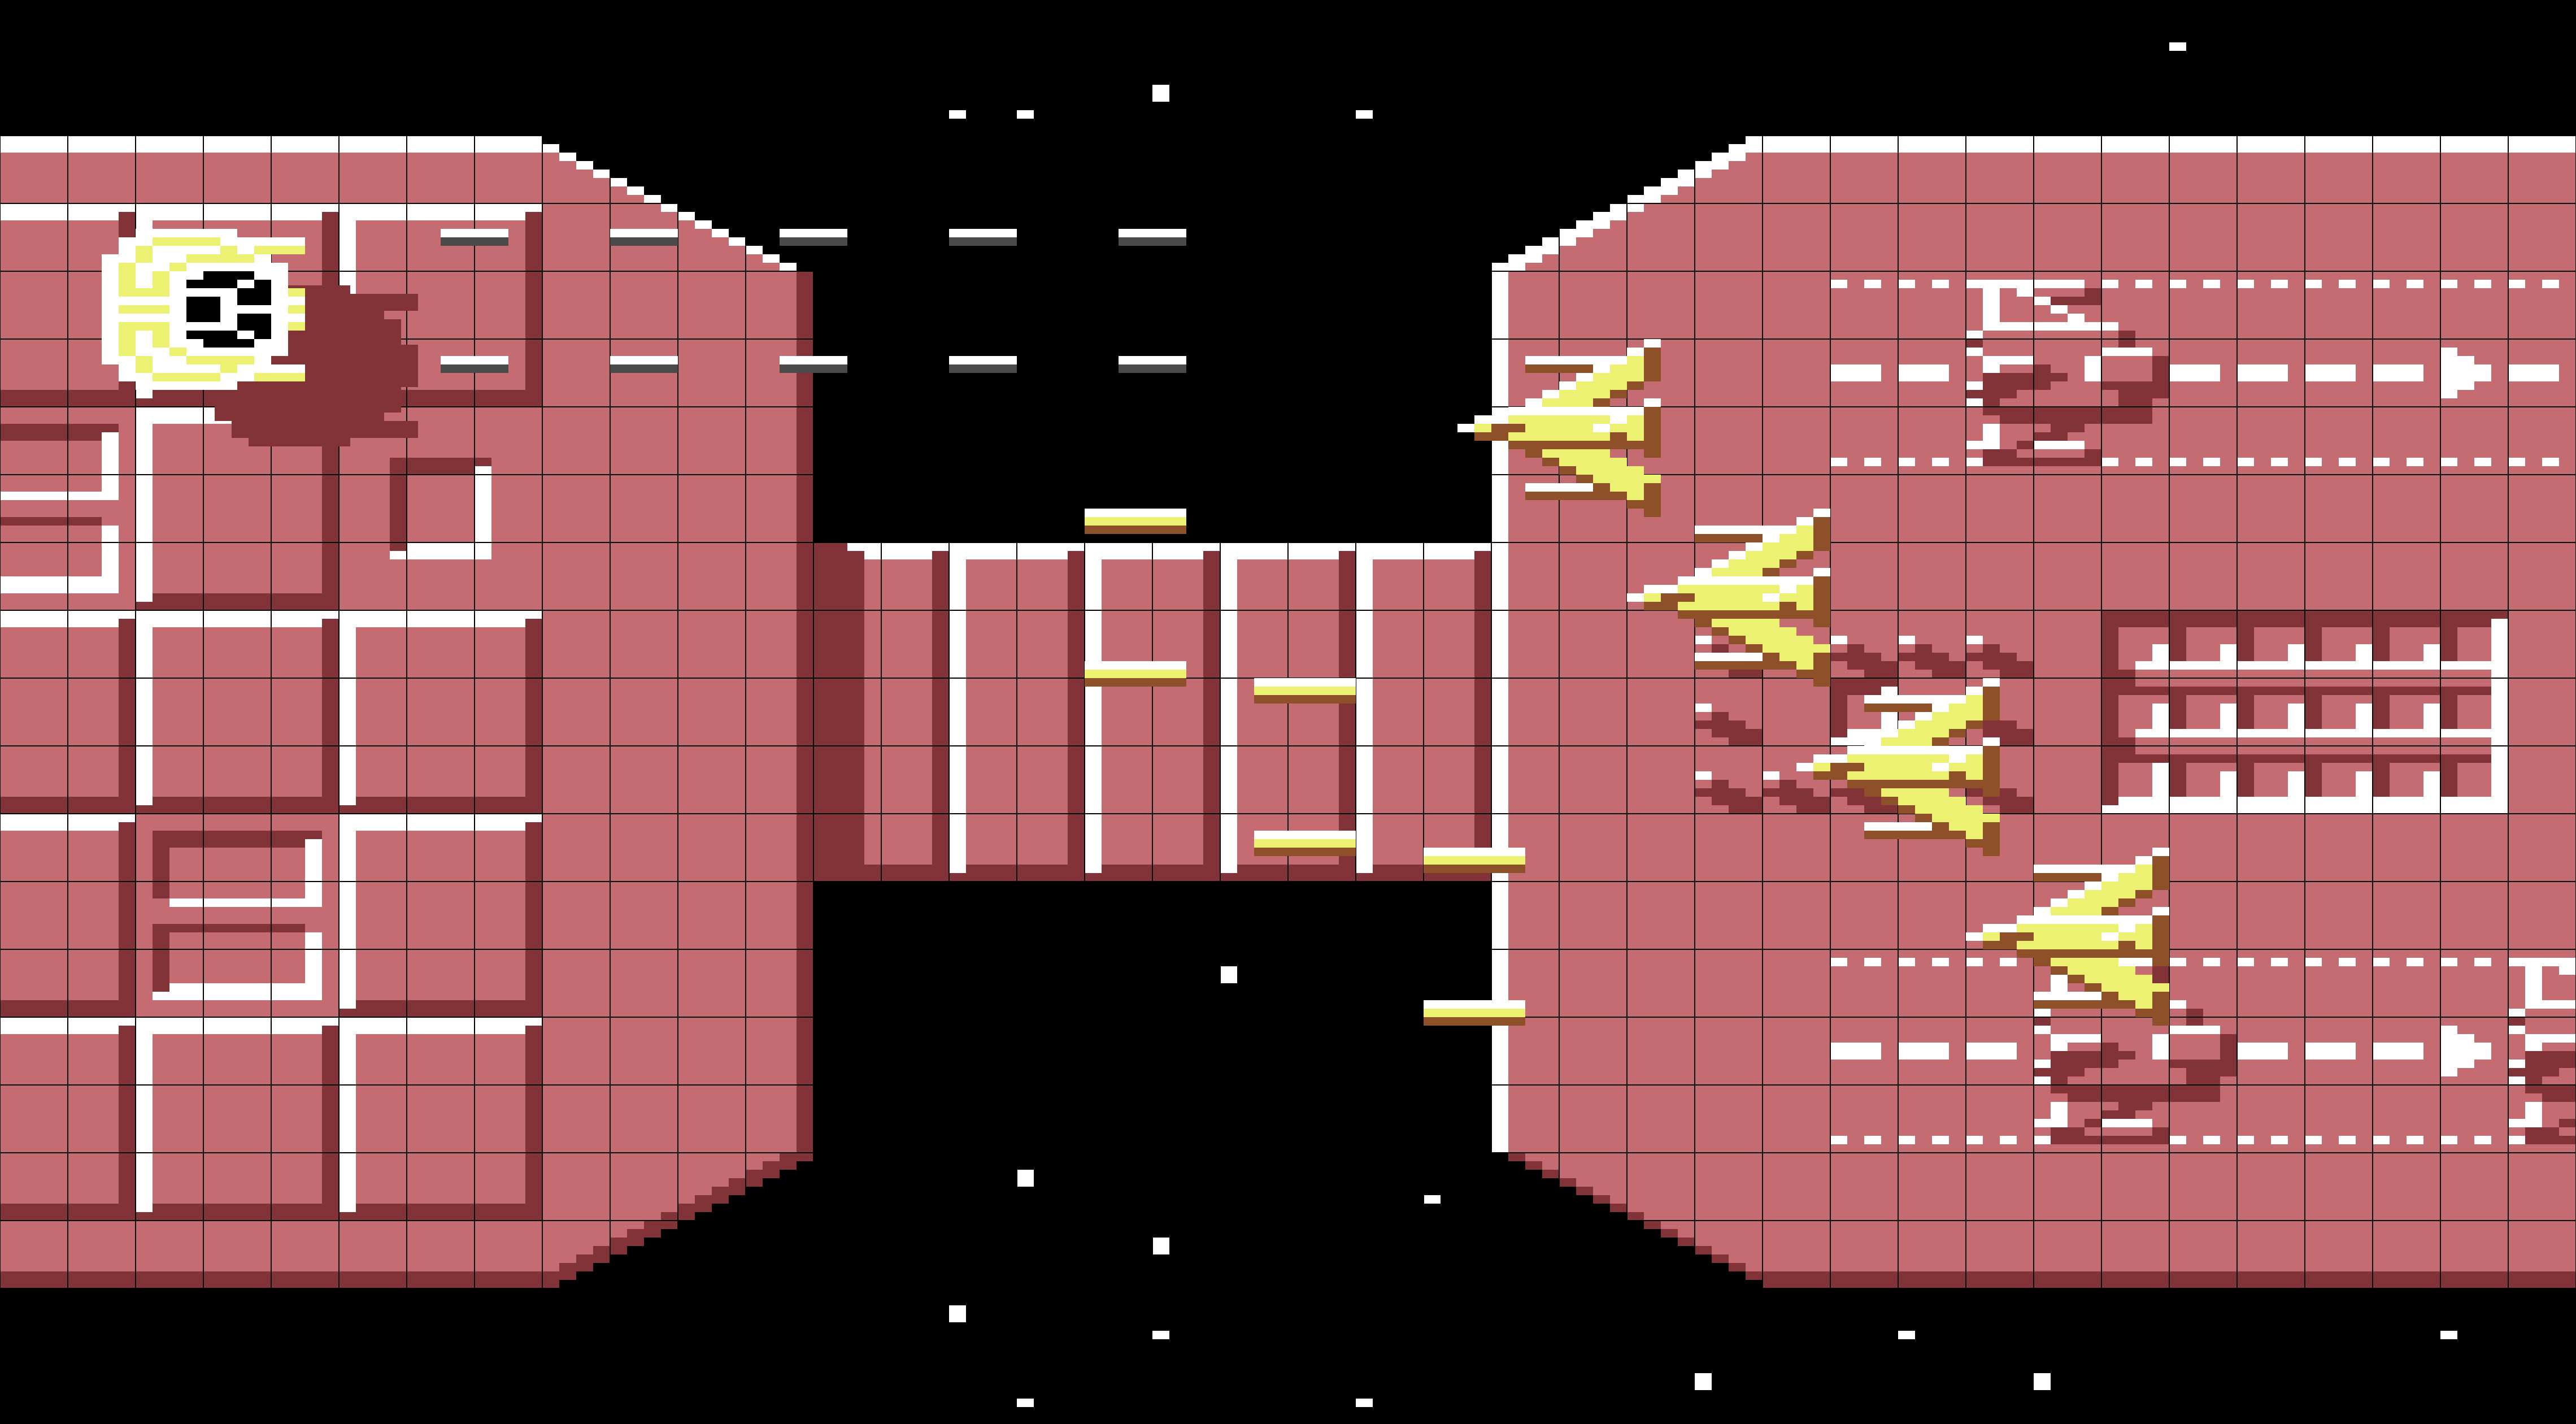

In [51]:
background = Image.new('RGBA', (cells(38), cells(21)), color="black")
for i in range(0,16):
    background = addRandomStar(background)

rows = [0,1,19,20]
for row in rows:
    background = addStarsToRow(background, row)

level = 15
diagram = get_surface_snippet(level=level, x_offset=cells(85), y_offset = cells(0), width=cells(38), height = cells(17))

"""
Add the manta
"""
img = Image.open(f"manta_sprites/{level}_MANTA1.png")
img = resize(img, FACTOR)
manta = img.copy()
shadow = make_shadow(manta.copy(), color=level_colors[level][2])
manta_pos = (scale(12),scale(10))
shadow_offset = (20*10,10*10)
diagram.paste(shadow, add_offset(manta_pos, shadow_offset), mask=shadow)
diagram.paste(manta, manta_pos, mask=manta)

"""
ADd Player Bulllets
"""
img = Image.new('RGBA', (8,2))
draw = ImageDraw.Draw(img)
draw.line((0,0,8,0), fill="white", width=1)
draw.line((0,1,8,1), fill=(0x4a, 0x4a, 0x4a, 255), width=1)
img = resize(img,FACTOR)
bullet = img
for o in range(52, 150, 20):
    manta_pos = (scale(o),scale(11))
    diagram.paste(bullet, manta_pos, mask=bullet)
    manta_pos = (scale(o),scale(26))
    diagram.paste(bullet, manta_pos, mask=bullet)


"""
Add the meanies
"""
img = Image.open(f"meanie_sprites/{level}_MEANIE_1E.png")
img = resize(img, FACTOR)
meanie = img.copy()
offset = 10
for o in range(1,5):
    meanie_pos = (scale(242 - offset),scale(94 - offset))
    diagram.paste(meanie, meanie_pos, mask=meanie)
    offset += 20

"""
Add the meanie bullets
"""
img = Image.open(f"meanie_bullet_sprites//{level}_BULLET_WIDE.png")
img = resize(img, FACTOR)
meanie = img.copy()
offset = 10
for o in range(1,4):
    meanie_pos = (scale(172 - offset),scale(94 - offset))
    diagram.paste(meanie, meanie_pos, mask=meanie)
    offset += 20


"""
Save the image
"""
background.paste(diagram, (0,cells(2)), mask=diagram)
background.save(f"preface/1.png")
background

## Scratchpad